# An Adapted Learned Policy

This native Julia companion retains the public observations, original Float64 design, path seeds, initial policy weights, training budgets, cost accounting and risk preference. Shared primitive normal draws and unfitted parameters preserve the original numerical inputs; Julia computes all generated prices, fitted policies, gradients, cash flows and risk summaries. Timings measure the current native run. Displayed date indices retain the original zero-based convention. Figures use the requested dark theme and native outputs are saved under `outputs/julia`.

## Separating training from independent evaluation

The learned position at date $k$ is written as

$$
\phi_k=f_{\theta}\!\left(T-t_k,\log(S_k/K),\phi_{k-1}\right).
$$

Here, $f_{\theta}$ is the released shared policy, $\theta$ contains its fitted parameters, $T-t_k$ is remaining time, $S_k$ is the current price, $K$ is the strike, and $\phi_{k-1}$ is the previous holding. No future price enters this mapping.

### Three Declared Training Seeds

Row,Item,Value
,String,Any
1,Training paths per seed,2048
2,Independent evaluation paths,8192
3,Training iterations,200
4,Hidden units per layer,16
5,Learning rate,0.003
6,Declared training seeds,"3301, 3302, 3303"
7,Evaluation seed,33999
8,Evaluation used for fitting or stopping,No


Row,Seed,Training path seed,Policy seed,Initial training risk,Final training risk,Smallest training risk,Independent evaluation risk,Training seconds
,Int64,Int64,Int64,Float64,Float64,Float64,Float64,Float64
1,3301,33011,33012,0.0323904,0.0316947,0.0316939,0.031404,123.827
2,3302,33021,33022,0.0334505,0.032465,0.0324644,0.0315226,17.9315
3,3303,33031,33032,0.0328552,0.0324679,0.0324668,0.0314355,24.4957


Row,Iteration,Seed,Training risk
,Int64,Int64,Float64
1,1,3301,0.0323904
2,10,3301,0.0317423
3,25,3301,0.0317152
4,50,3301,0.0316973
5,100,3301,0.031695
6,150,3301,0.0316941
7,200,3301,0.0316947
8,1,3302,0.0334505
9,10,3302,0.0325439


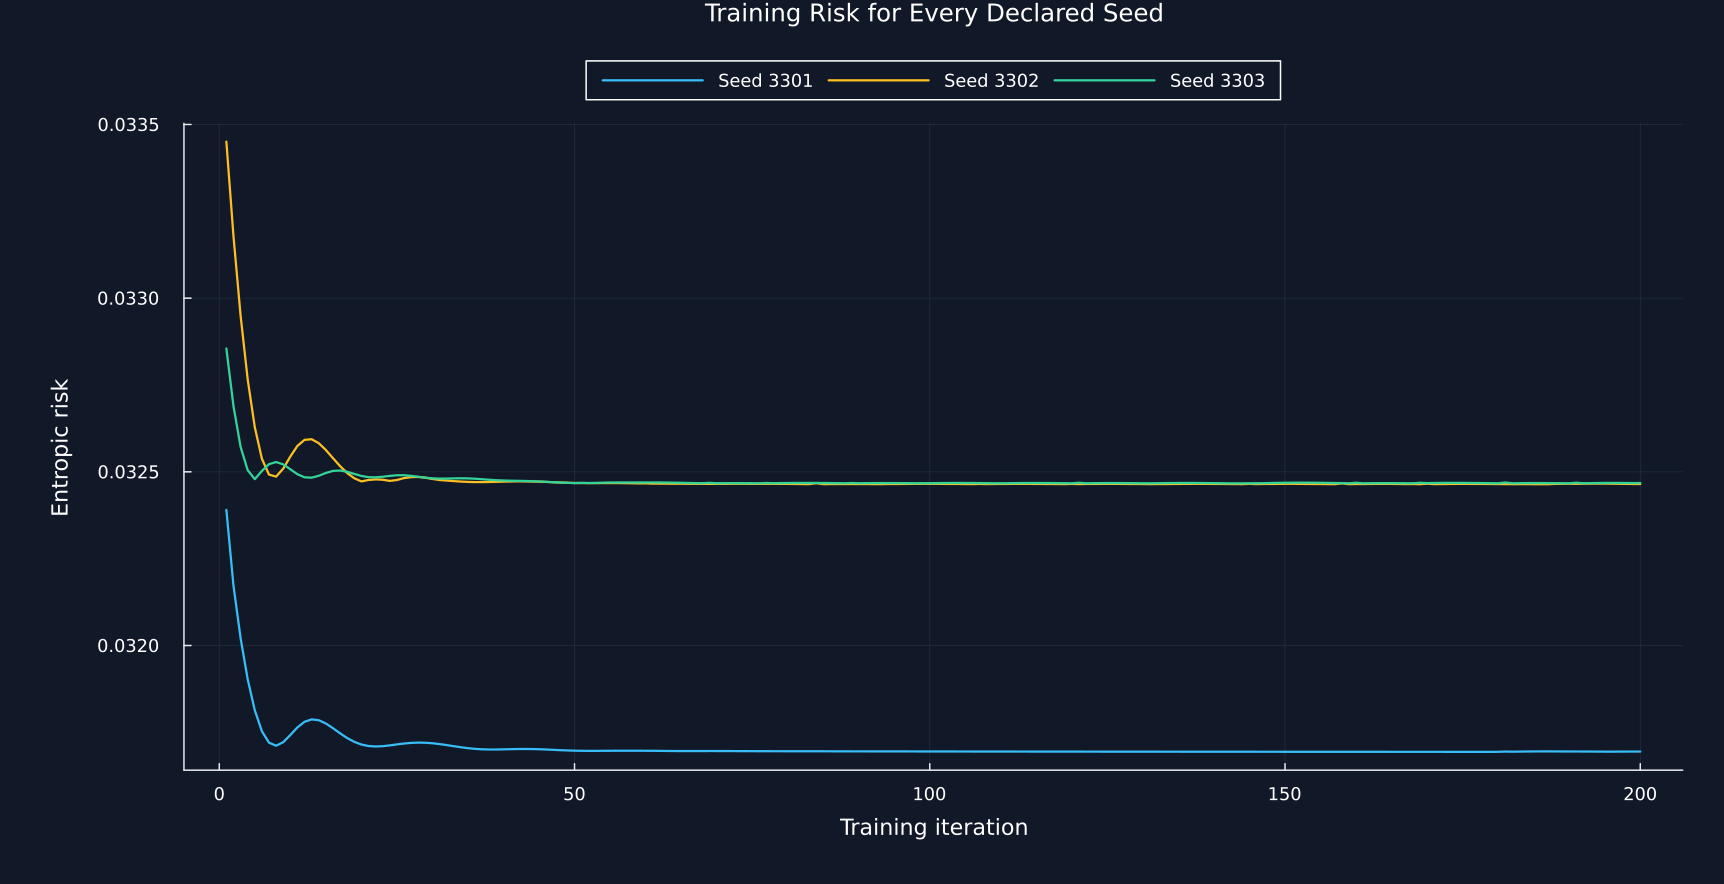

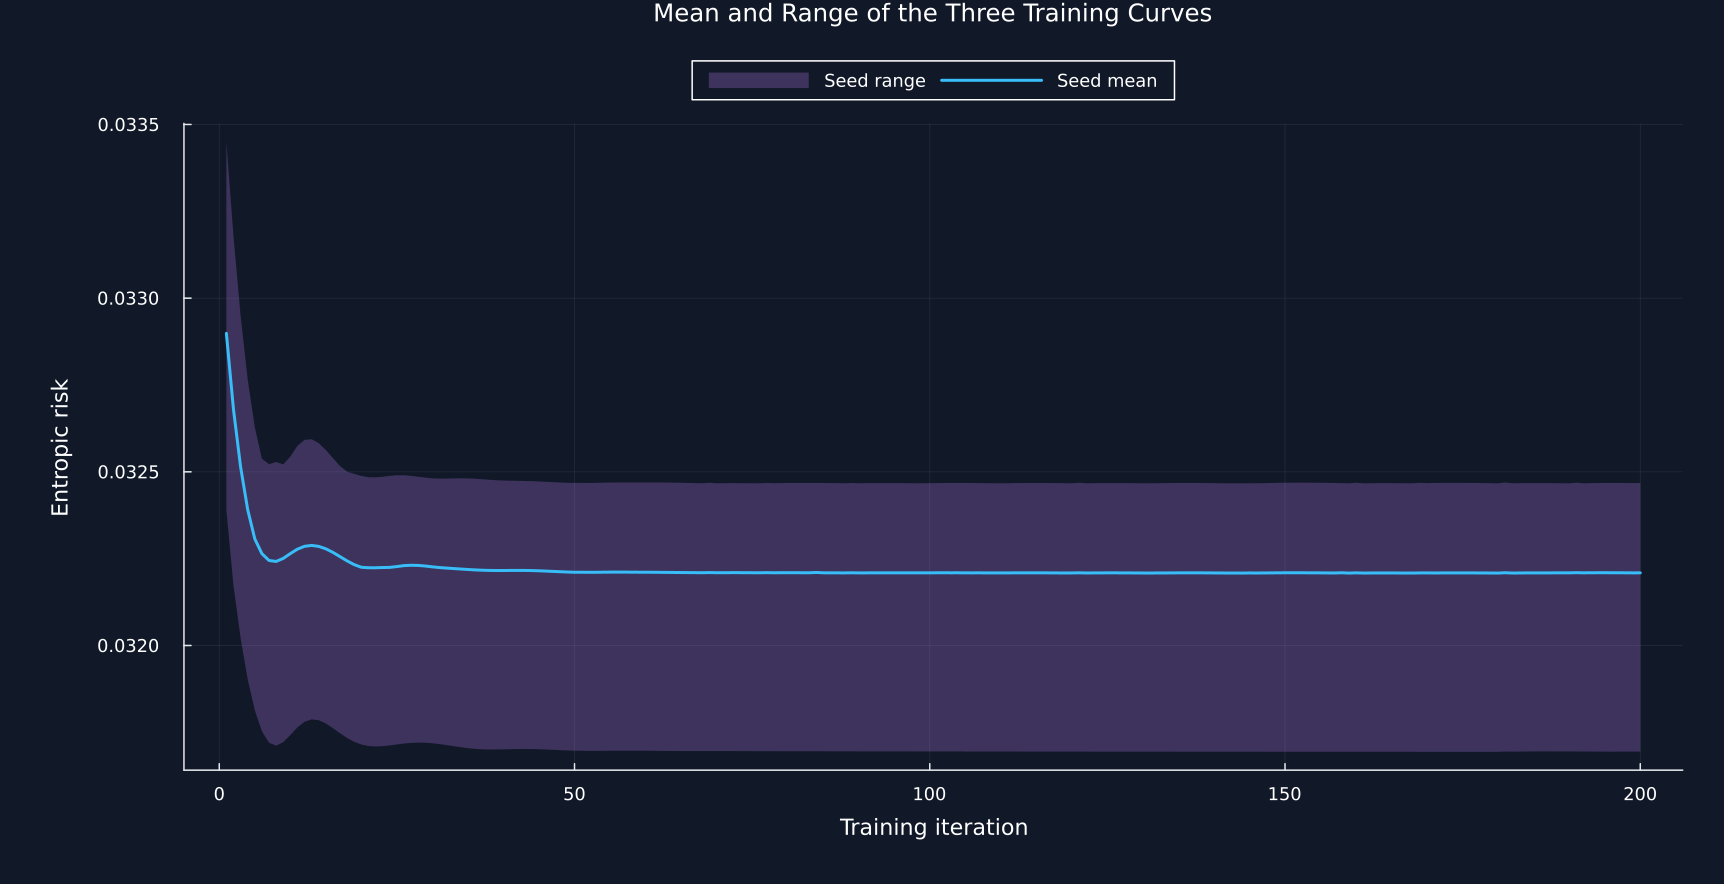

In [1]:
using RiskLabAI, Random, Statistics, LinearAlgebra, DataFrames, Dates, Plots
include(joinpath("..", "support", "BookSupport.jl"))
using .BookSupport
import .BookSupport: palette
@assert pkgversion(RiskLabAI) == v"0.6.2"
configure_plots!()
paths = output_paths("31_deep_hedging");
using CSV, TOML, Printf, Zygote
include(joinpath("..","support","BookHedging.jl"))
using .BookHedging
using RiskLabAI.Backtest: gbm_hedging_paths,black_scholes_call_delta,hedging_pnl,entropic_risk,DeepHedge,train_deep_hedge
default(left_margin=12Plots.mm,bottom_margin=10Plots.mm)
violet = "#C084FC"
random_root = joinpath("..","data","chapter31_random_inputs")
artifacts = joinpath(book_root(),"outputs","julia","artifacts","31_deep_hedging")
mkpath(artifacts)
data_file = dataset_path("fred_nasdaq")
full_public,public_design,public_observed,public_returns,sigma = public_volatility(data_file)
design = (spot=1.0,strike=1.0,maturity_days=30,maturity=30/365,volatility=sigma,drift=0.0,steps=20,cost_rate=.002,risk_aversion=3.0,hidden_size=16,learning_rate=.003,training_paths=2048,evaluation_paths=8192,iterations=200)
function table(frame,name,caption)
    shown = copy(frame)
    for column in names(shown)
        if eltype(shown[!,column])<:Bool
            shown[!,column] = ifelse.(shown[!,column],"Pass","Fail")
        end
    end
    save_table(shown,paths,name;caption,label="tab:chapter33-"*replace(name,"_"=>"-"))
    return nothing
end
function histogram_geometry(values,bins;density=false)
    lower,upper = extrema(values)
    if lower==upper
        lower,upper = lower-.5,upper+.5
    end
    edges = collect(range(lower,upper;length=bins+1))
    counts = zeros(Int,bins)
    for value in values
        index = clamp(searchsortedlast(edges,value),1,bins)
        counts[index] += 1
    end
    @assert sum(counts)==length(values)
    heights = density ? counts./length(values)./diff(edges) : Float64.(counts)
    return edges,heights
end
function draw_histogram!(figure,values,bins;color,label="",density=false,outline=false)
    edges,heights = histogram_geometry(values,bins;density)
    if outline
        x = vcat(edges[1],vec(permutedims(hcat(edges[1:end-1],edges[2:end]))),edges[end])
        y = vcat(0.0,repeat(heights;inner=2),0.0)
        plot!(figure,x,y;color,label,linewidth=1.7)
    else
        bar!(figure,(edges[1:end-1]+edges[2:end])/2,heights;bar_width=diff(edges),color,label,linealpha=0,alpha=.9)
    end
    return nothing
end
training_seeds = [3301,3302,3303]
evaluation_seed = 33999
evaluation_prices = hedge_paths(random_root,evaluation_seed,design.evaluation_paths,design.steps,sigma)
function fitted_model(seed)
    return DeepHedge(design.hidden_size;seed=seed*10+2,parameters=read_parameters(joinpath(artifacts,"deep_hedge_seed_$(seed).toml")))
end
training_contract = DataFrame("Item"=>["Training paths per seed","Independent evaluation paths","Training iterations","Hidden units per layer","Learning rate","Declared training seeds","Evaluation seed","Evaluation used for fitting or stopping"],"Value"=>Any[design.training_paths,design.evaluation_paths,design.iterations,design.hidden_size,design.learning_rate,join(training_seeds,", "),evaluation_seed,"No"])
table(training_contract,"deep_hedging_training_contract","Fixed training and evaluation contract.")
histories,run_rows = NamedTuple[],NamedTuple[]
for seed in training_seeds
    path_seed,model_seed = seed*10+1,seed*10+2
    training_prices = hedge_paths(random_root,path_seed,design.training_paths,design.steps,sigma)
    model = initial_model(random_root,model_seed)
    elapsed = @elapsed history = train_deep_hedge(model,training_prices;strike=design.strike,maturity=design.maturity,cost_rate=design.cost_rate,risk_aversion=design.risk_aversion,iterations=design.iterations,learning_rate=design.learning_rate)
    @assert all(isfinite,history)
    positions = model(evaluation_prices;strike=design.strike,maturity=design.maturity)
    evaluation_pnl = hedging_pnl(evaluation_prices,positions;strike=design.strike,cost_rate=design.cost_rate)
    evaluation_risk = entropic_risk(evaluation_pnl,design.risk_aversion)
    save_parameters(joinpath(artifacts,"deep_hedge_seed_$(seed).toml"),model.parameters)
    for (index,value) in enumerate(history)
        push!(histories,(Iteration=index,Seed=seed,risk=value))
    end
    push!(run_rows,(Seed=seed,path_seed=path_seed,model_seed=model_seed,initial=history[1],final=history[end],smallest=minimum(history),evaluation=evaluation_risk,seconds=elapsed))
end
history_frame = rename!(DataFrame(histories),["Iteration","Seed","Training risk"])
run_summary = rename!(DataFrame(run_rows),["Seed","Training path seed","Policy seed","Initial training risk","Final training risk","Smallest training risk","Independent evaluation risk","Training seconds"])
CSV.write(joinpath(artifacts,"primary_training_histories.csv"),history_frame)
CSV.write(joinpath(artifacts,"primary_training_runs.csv"),run_summary)
table(run_summary,"deep_hedging_training_run_summary","All declared primary training runs and independent evaluation risks.")
checkpoints = history_frame[in.(history_frame.Iteration,Ref([1,10,25,50,100,150,200])),:]
table(checkpoints,"deep_hedging_learning_curve_checkpoints","Training-risk checkpoints for every declared seed.")
save_data(history_frame,paths,"deep_hedging_training_curves")
figure = plot(;title="Training Risk for Every Declared Seed",xlabel="Training iteration",ylabel="Entropic risk",legend=:outertop,legend_columns=3,size=(1150,590))
for (seed,color) in zip(training_seeds,[palette.cyan,palette.amber,palette.green])
    selected = history_frame[history_frame.Seed.==seed,:]
    plot!(figure,selected.Iteration,selected[!,"Training risk"];color,label="Seed $(seed)",linewidth=1.5)
end
save_figure(figure,paths,"deep_hedging_training_curves")
matrix = hcat([history_frame[history_frame.Seed.==seed,"Training risk"] for seed in training_seeds]...)
curve_band = DataFrame("Iteration"=>1:design.iterations,"Mean"=>vec(mean(matrix;dims=2)),"Minimum"=>vec(minimum(matrix;dims=2)),"Maximum"=>vec(maximum(matrix;dims=2)))
save_data(curve_band,paths,"deep_hedging_training_curve_band")
figure = plot(curve_band.Iteration,curve_band.Minimum;fillrange=curve_band.Maximum,color=violet,fillalpha=.25,linealpha=0,label="Seed range",title="Mean and Range of the Three Training Curves",xlabel="Training iteration",ylabel="Entropic risk",legend=:outertop,legend_columns=2,size=(1150,590))
plot!(figure,curve_band.Iteration,curve_band.Mean;color=palette.cyan,label="Seed mean")
save_figure(figure,paths,"deep_hedging_training_curve_band")
nothing


## Enforcing the information boundary in fitted positions

Adaptation requires

$$
\phi_k\in\mathcal{F}_k,
$$

where $\mathcal{F}_k$ contains information available through date $k$. The condition says that the holding $\phi_k$ may depend on current and earlier observations, but it cannot depend on $S_{k+1},\ldots,S_N$. The numerical check changes only future prices and verifies that earlier positions remain identical.

### Verifying causal dependence through gradients

Row,Check,Value,Pass
,String,Float64,String
1,Largest earlier-position difference,0.0,Pass
2,Largest later-position difference,0.00168992,Pass
3,Future prices changed only after date,10.0,Pass


Row,Check,Value,Pass
,String,Any,String
1,Training and evaluation seeds differ,33011 and 33999,Pass
2,Training and evaluation arrays differ,true,Pass
3,Evaluation paths used after fitting,Yes,Pass
4,Evaluation result selected stopping time,No,Pass


Row,Check,Value,Pass
,String,Any,String
1,Risk is finite,0.0375166,Pass
2,All gradients are finite,true,Pass
3,Largest absolute gradient,0.016573,Pass


Row,Trading date,Fifth percentile,First quartile,Median,Third quartile,Ninety-fifth percentile
,Int64,Float64,Float64,Float64,Float64,Float64
1,0,0.254135,0.254135,0.254135,0.254135,0.254135
2,5,0.264653,0.26488,0.265015,0.265133,0.265269
3,10,0.264294,0.264656,0.264874,0.265056,0.265245
4,15,0.263886,0.264408,0.264709,0.264956,0.265204
5,19,0.26357,0.264204,0.264567,0.264853,0.265154


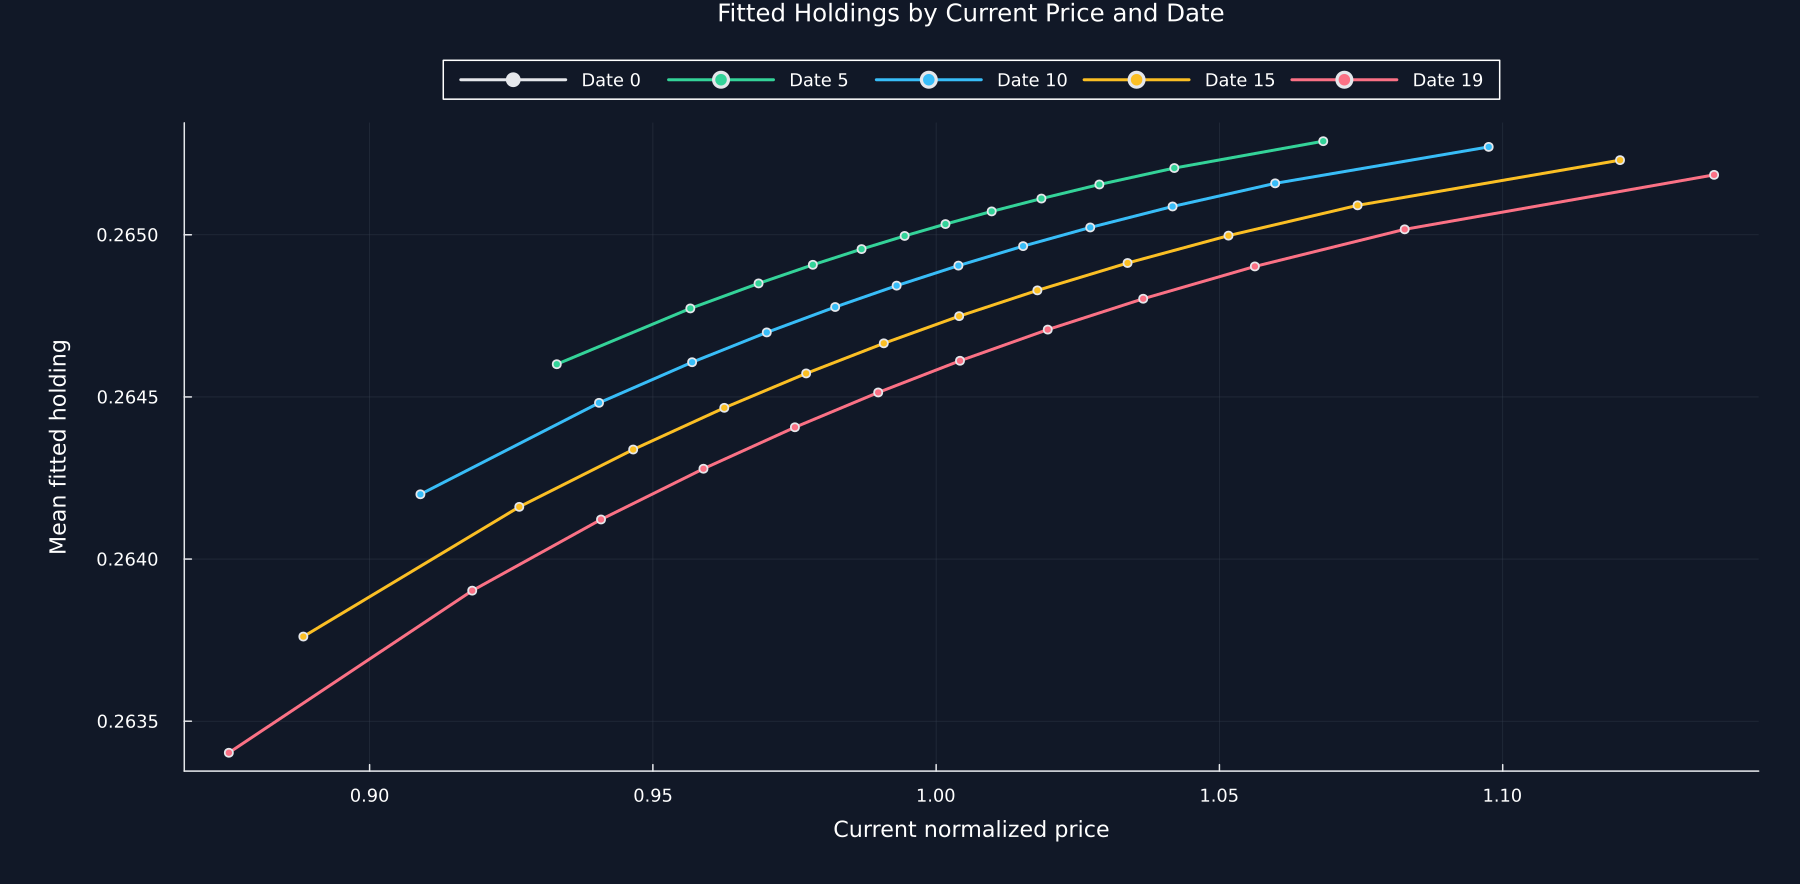

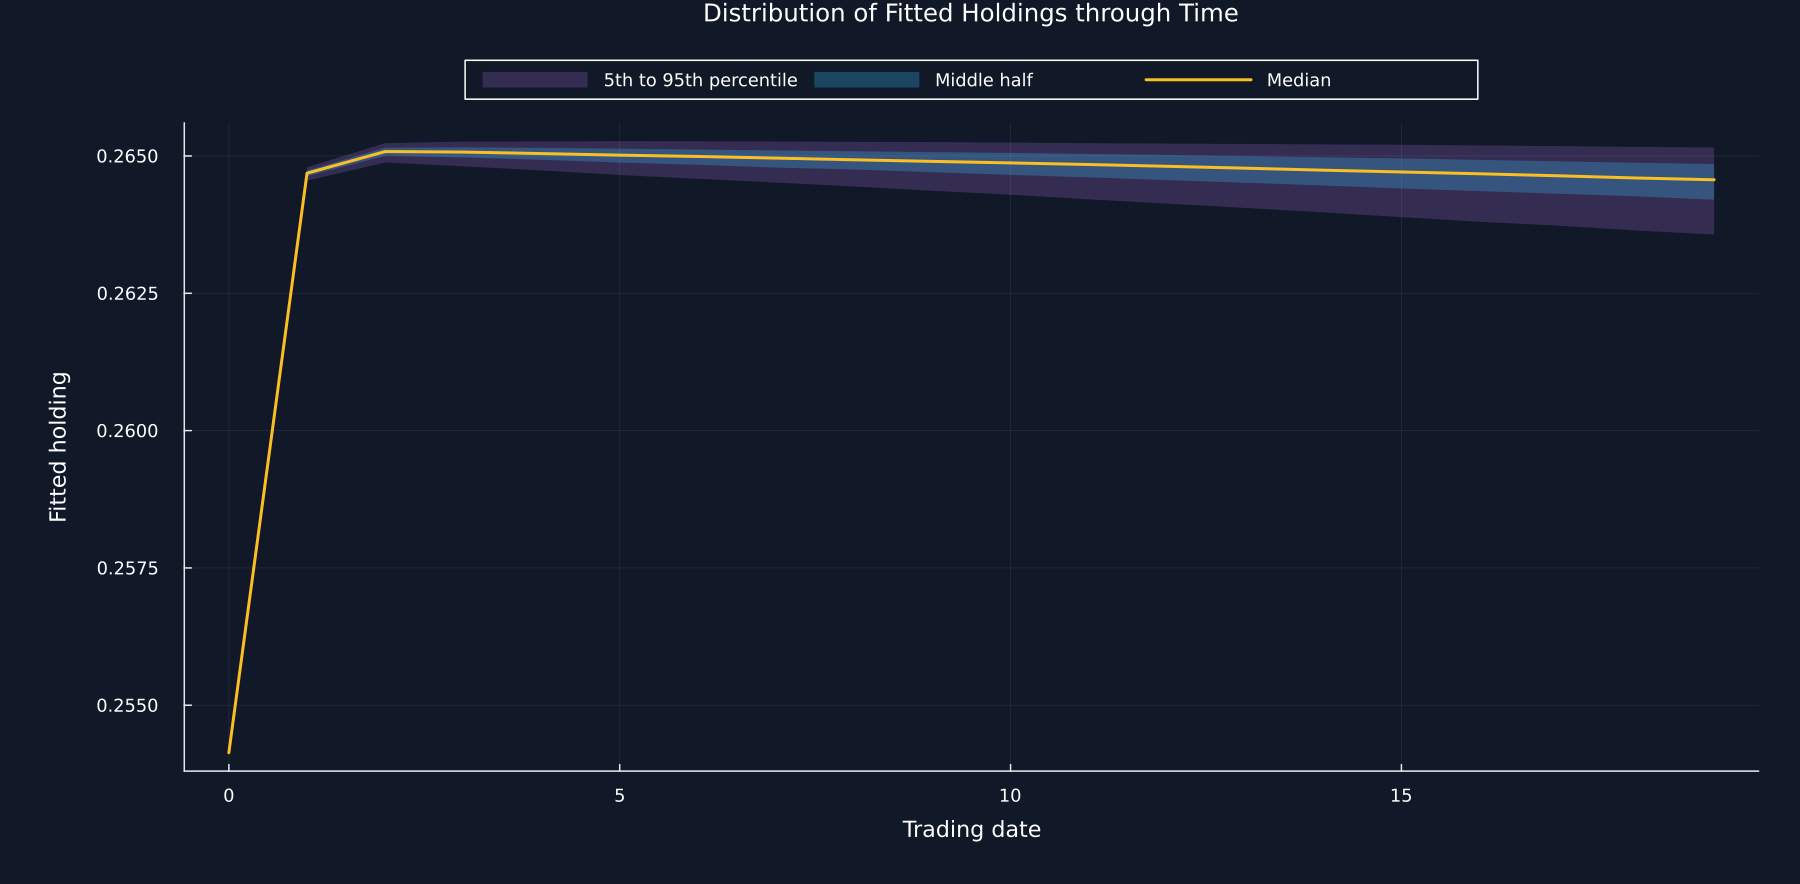

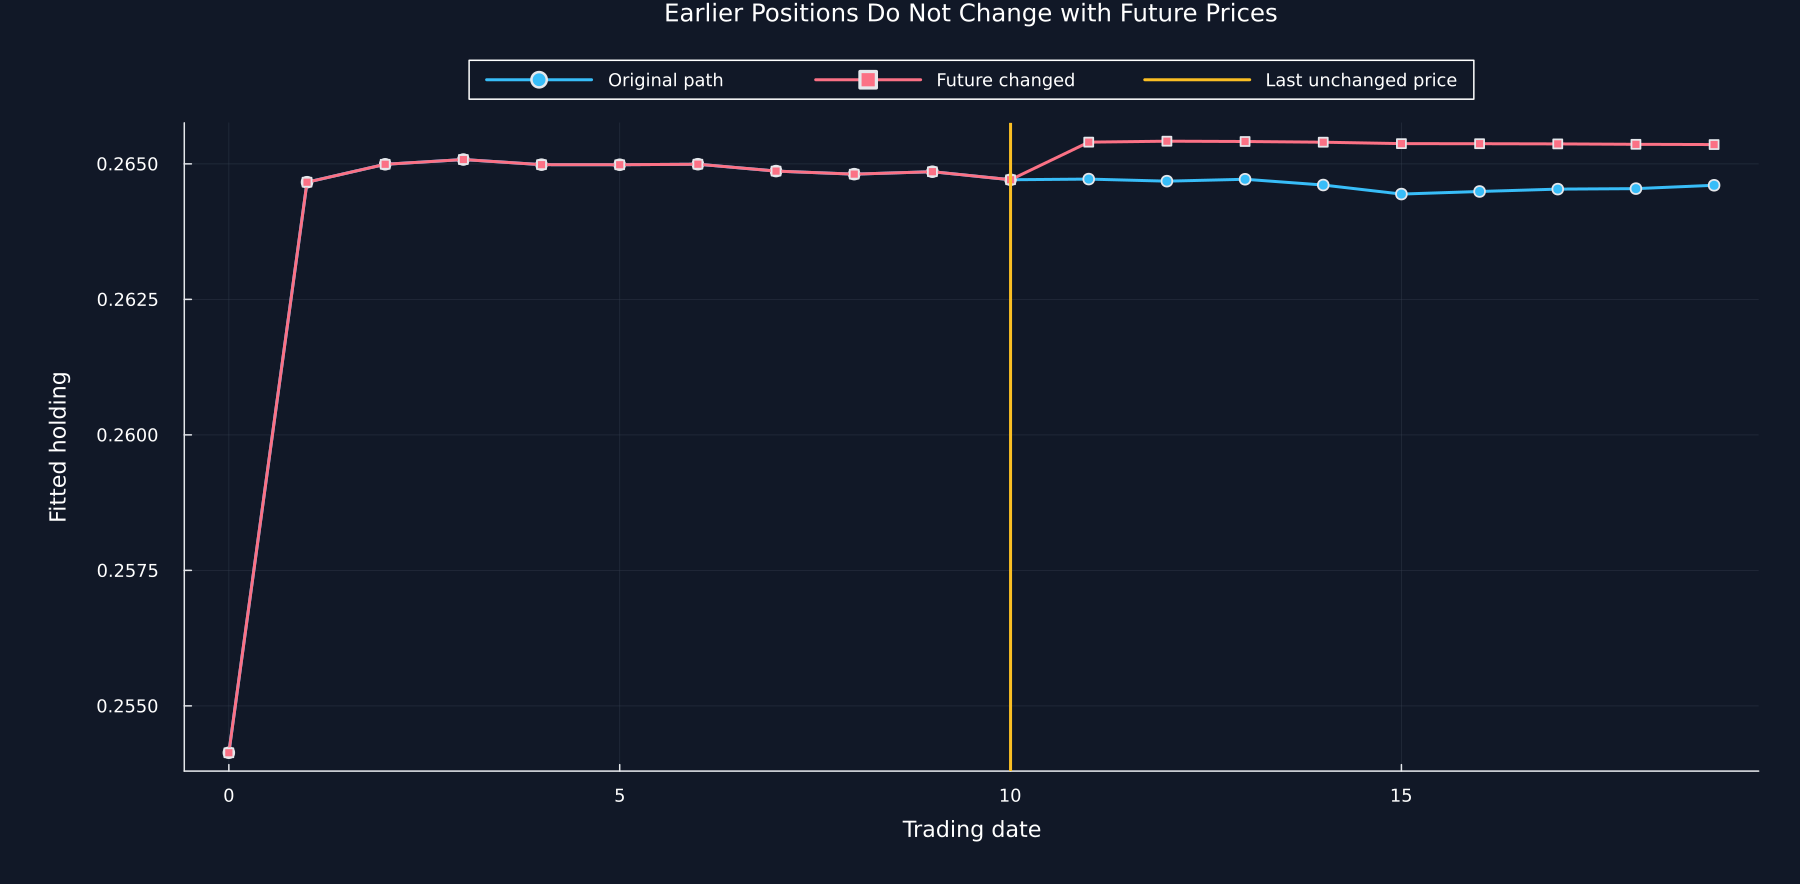

Row,Seed,Training seconds
,Int64,Float64
1,3301,123.827
2,3302,17.9315
3,3303,24.4957


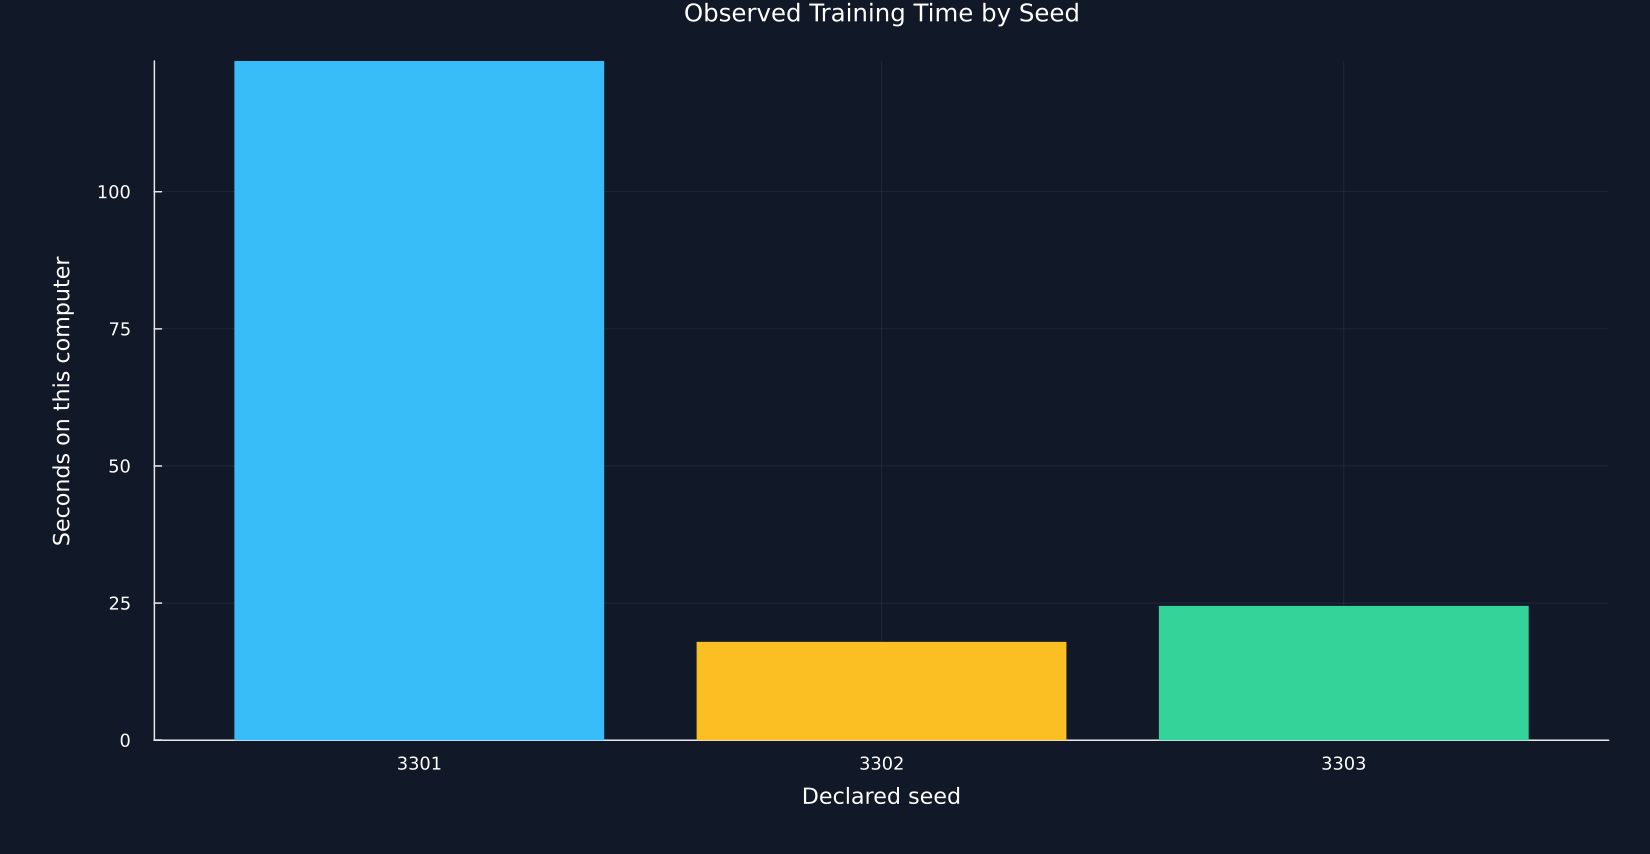

In [2]:
model = fitted_model(training_seeds[1])
base = copy(evaluation_prices[1:128,:])
changed = copy(base)
cut = 10
changed[:,cut+2:end] .*= 1.25
base_positions = model(base;strike=design.strike,maturity=design.maturity)
changed_positions = model(changed;strike=design.strike,maturity=design.maturity)
early_difference = maximum(abs.(base_positions[:,1:cut+1]-changed_positions[:,1:cut+1]))
later_difference = maximum(abs.(base_positions[:,cut+2:end]-changed_positions[:,cut+2:end]))
adaptation = DataFrame("Check"=>["Largest earlier-position difference","Largest later-position difference","Future prices changed only after date"],"Value"=>[early_difference,later_difference,cut],"Pass"=>[early_difference==0,later_difference>0,base[:,1:cut+1]==changed[:,1:cut+1]])
@assert all(adaptation.Pass)
table(adaptation,"deep_hedging_adaptation_checks","Changing future prices leaves earlier fitted positions unchanged.")
training_prices_check = hedge_paths(random_root,training_seeds[1]*10+1,design.evaluation_paths,design.steps,sigma)
independence = DataFrame("Check"=>["Training and evaluation seeds differ","Training and evaluation arrays differ","Evaluation paths used after fitting","Evaluation result selected stopping time"],"Value"=>Any["$(training_seeds[1]*10+1) and $(evaluation_seed)"!="Yes","No"],"Pass"=>[training_seeds[1]*10+1!=evaluation_seed!=true,true])
@assert all(independence.Pass)
table(independence,"deep_hedging_independence_checks","Training and final evaluation remain separate.")
objective(parameters) = entropic_risk(hedging_pnl(base,RiskLabAI.Backtest._deep_hedge_positions(parameters,base,design.strike,design.maturity);strike=design.strike,cost_rate=design.cost_rate),design.risk_aversion)
gradient_risk = objective(model.parameters)
gradient = only(Zygote.gradient(objective,model.parameters))
gradient_values = reduce(vcat,[vec(value) for value in values(gradient)])
gradient_checks = DataFrame("Check"=>["Risk is finite","All gradients are finite","Largest absolute gradient"],"Value"=>Any[gradient_risk,all(isfinite,gradient_values),maximum(abs,gradient_values)],"Pass"=>[isfinite(gradient_risk),all(isfinite,gradient_values),maximum(abs,gradient_values)>0])
@assert all(gradient_checks.Pass)
table(gradient_checks,"deep_hedging_gradient_checks","Finite risk and gradient checks after primary training.")
all_positions = model(evaluation_prices;strike=design.strike,maturity=design.maturity)
position_rows,surface_rows = NamedTuple[],NamedTuple[]
for index in 0:design.steps-1
    holdings = all_positions[:,index+1]
    q = quantile(holdings,[.05,.25,.5,.75,.95])
    push!(position_rows,(date=index,fifth=q[1],first=q[2],median=q[3],third=q[4],ninety_fifth=q[5]))
    if index in [0,5,10,15,19]
        prices_now = evaluation_prices[:,index+1]
        edges = unique(quantile(prices_now,collect(0:12)./12))
        for bin in 1:length(edges)-1
            mask = (bin==1 ? prices_now.>=edges[bin] : prices_now.>edges[bin]).&(prices_now.<=edges[bin+1])
            any(mask) || continue
            push!(surface_rows,(date=index,price=mean(prices_now[mask]),holding=mean(holdings[mask])))
        end
    end
end
position_summary = rename!(DataFrame(position_rows),["Trading date","Fifth percentile","First quartile","Median","Third quartile","Ninety-fifth percentile"])
table(position_summary[in.(position_summary[!,"Trading date"],Ref([0,5,10,15,19])),:],"deep_hedging_position_summary","Selected fitted-position summaries over the trading horizon.")
surface = rename!(DataFrame(surface_rows),["Trading date","Current price","Mean holding"])
save_data(surface,paths,"deep_hedging_position_surface")
figure = plot(;title="Fitted Holdings by Current Price and Date",xlabel="Current normalized price",ylabel="Mean fitted holding",legend=:outertop,legend_columns=5,size=(1200,590))
for (index,color) in zip([0,5,10,15,19],[palette.text,palette.green,palette.cyan,palette.amber,palette.rose])
    selected = surface[surface[!,"Trading date"].==index,:]
    plot!(figure,selected[!,"Current price"],selected[!,"Mean holding"];color,marker=:circle,markersize=3,label="Date $(index)")
end
save_figure(figure,paths,"deep_hedging_position_surface")
save_data(position_summary,paths,"deep_hedging_holding_quantiles")
figure = plot(position_summary[!,"Trading date"],position_summary[!,"Fifth percentile"];fillrange=position_summary[!,"Ninety-fifth percentile"],color=violet,fillalpha=.2,linealpha=0,label="5th to 95th percentile",title="Distribution of Fitted Holdings through Time",xlabel="Trading date",ylabel="Fitted holding",legend=:outertop,legend_columns=3,size=(1200,590))
plot!(figure,position_summary[!,"Trading date"],position_summary[!,"First quartile"];fillrange=position_summary[!,"Third quartile"],color=palette.cyan,fillalpha=.28,linealpha=0,label="Middle half")
plot!(figure,position_summary[!,"Trading date"],position_summary.Median;color=palette.amber,label="Median")
save_figure(figure,paths,"deep_hedging_holding_quantiles")
adaptation_figure = DataFrame("Date"=>0:design.steps-1,"Original position"=>base_positions[1,:],"Changed-future position"=>changed_positions[1,:])
save_data(adaptation_figure,paths,"deep_hedging_adaptation_path")
figure = plot(adaptation_figure.Date,adaptation_figure[!,"Original position"];color=palette.cyan,marker=:circle,label="Original path",title="Earlier Positions Do Not Change with Future Prices",xlabel="Trading date",ylabel="Fitted holding",legend=:outertop,legend_columns=3,size=(1200,590))
plot!(figure,adaptation_figure.Date,adaptation_figure[!,"Changed-future position"];color=palette.rose,marker=:square,markersize=3,label="Future changed")
vline!(figure,[cut];color=palette.amber,label="Last unchanged price")
save_figure(figure,paths,"deep_hedging_adaptation_path")
time_table = run_summary[:,["Seed","Training seconds"]]
table(time_table,"deep_hedging_training_time","Observed computer training time for every declared seed.")
save_data(time_table,paths,"deep_hedging_training_time")
figure = bar(1:3,time_table[!,"Training seconds"];color=[palette.cyan,palette.amber,palette.green],linealpha=0,xticks=(1:3,string.(time_table.Seed)),title="Observed Training Time by Seed",xlabel="Declared seed",ylabel="Seconds on this computer",legend=false,size=(1100,570))
save_figure(figure,paths,"deep_hedging_training_time")
nothing


## Independent Outcomes for Every Fitted Policy

For each declared seed $j$, the reported final risk is

$$
\widehat\rho_j=\frac{1}{\lambda}\log\!\left(\frac{1}{M}\sum_{i=1}^{M}e^{-\lambda P_{ij}}\right).
$$

Here, $M$ is the fixed number of independent evaluation paths and $P_{ij}$ is the terminal cash flow for evaluation path $i$ under the policy fitted with seed $j$. Every seed is retained; no evaluation result chooses a policy or changes the number of training iterations.

Row,Strategy,Entropic risk,Mean cash flow,Cash flow standard deviation,Fifth percentile,Mean loss in worst five percent,Mean turnover,Mean trading cost,Mean payoff
,String,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64
1,Learned seed 3301,0.031404,-0.0300421,0.0293008,-0.0945894,0.11859,0.530783,0.00106157,0.028887
2,Learned seed 3302,0.0315226,-0.0306309,0.0239633,-0.0788033,0.0977474,0.800167,0.00160033,0.028887
3,Learned seed 3303,0.0314355,-0.0303949,0.0257734,-0.0846277,0.105965,0.692083,0.00138417,0.028887


Row,Quantity,Value
,String,Float64
1,Smallest learned-policy risk,0.031404
2,Largest learned-policy risk,0.0315226
3,Mean learned-policy risk,0.031454
4,Risk range,0.000118676


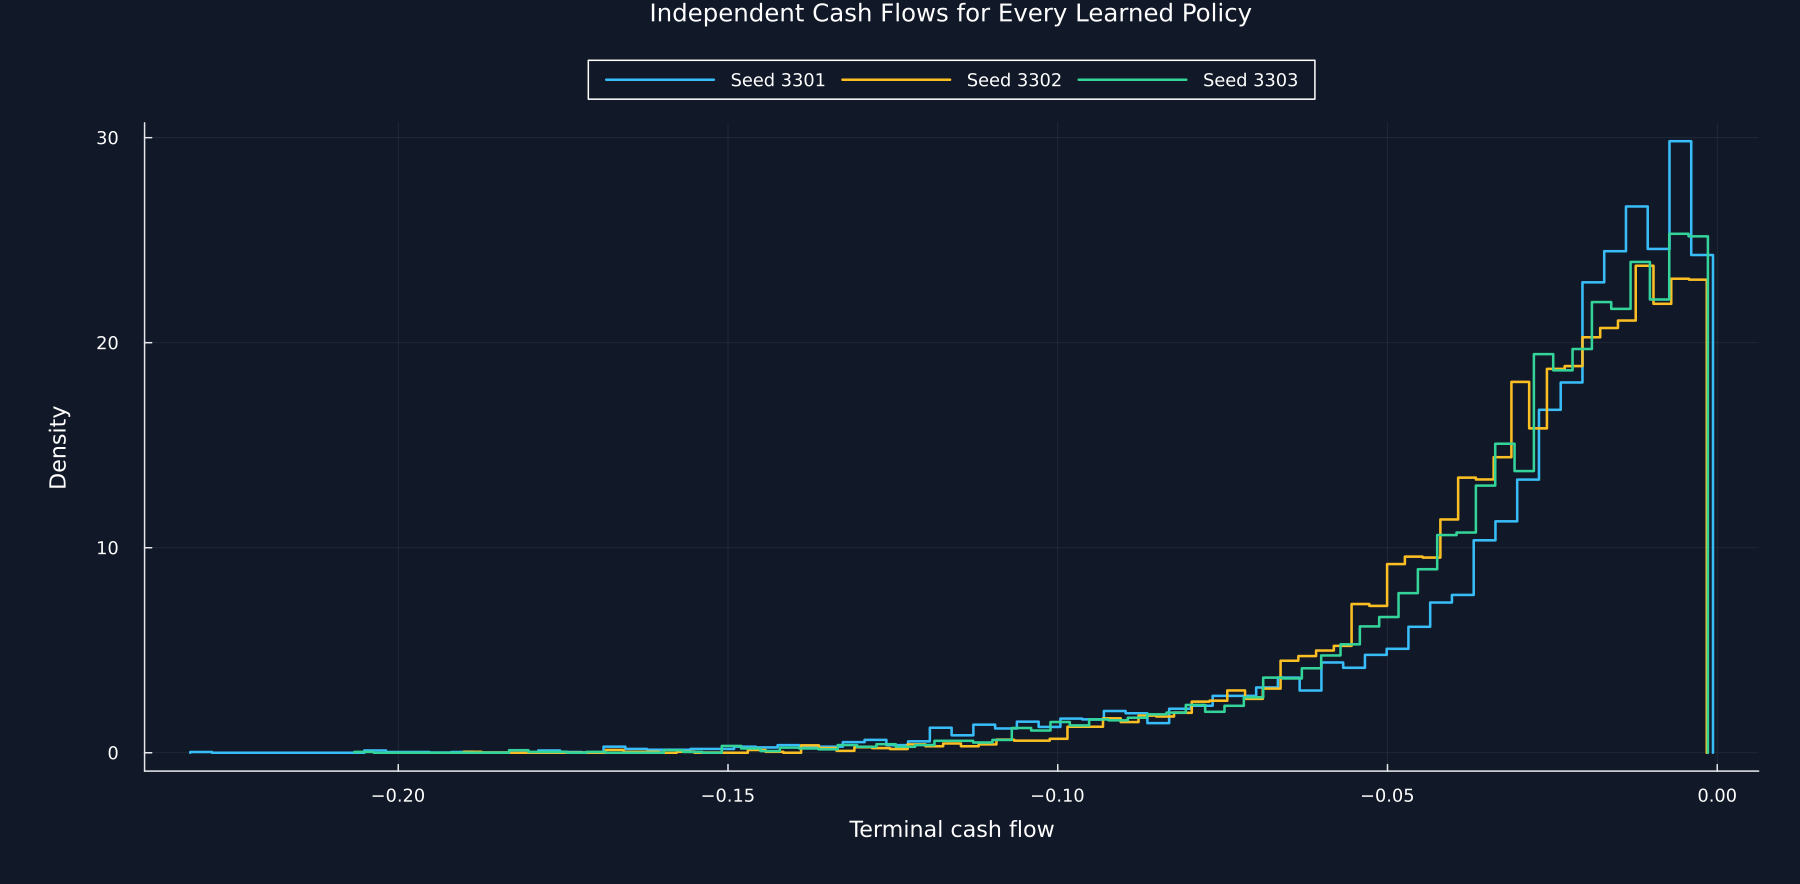

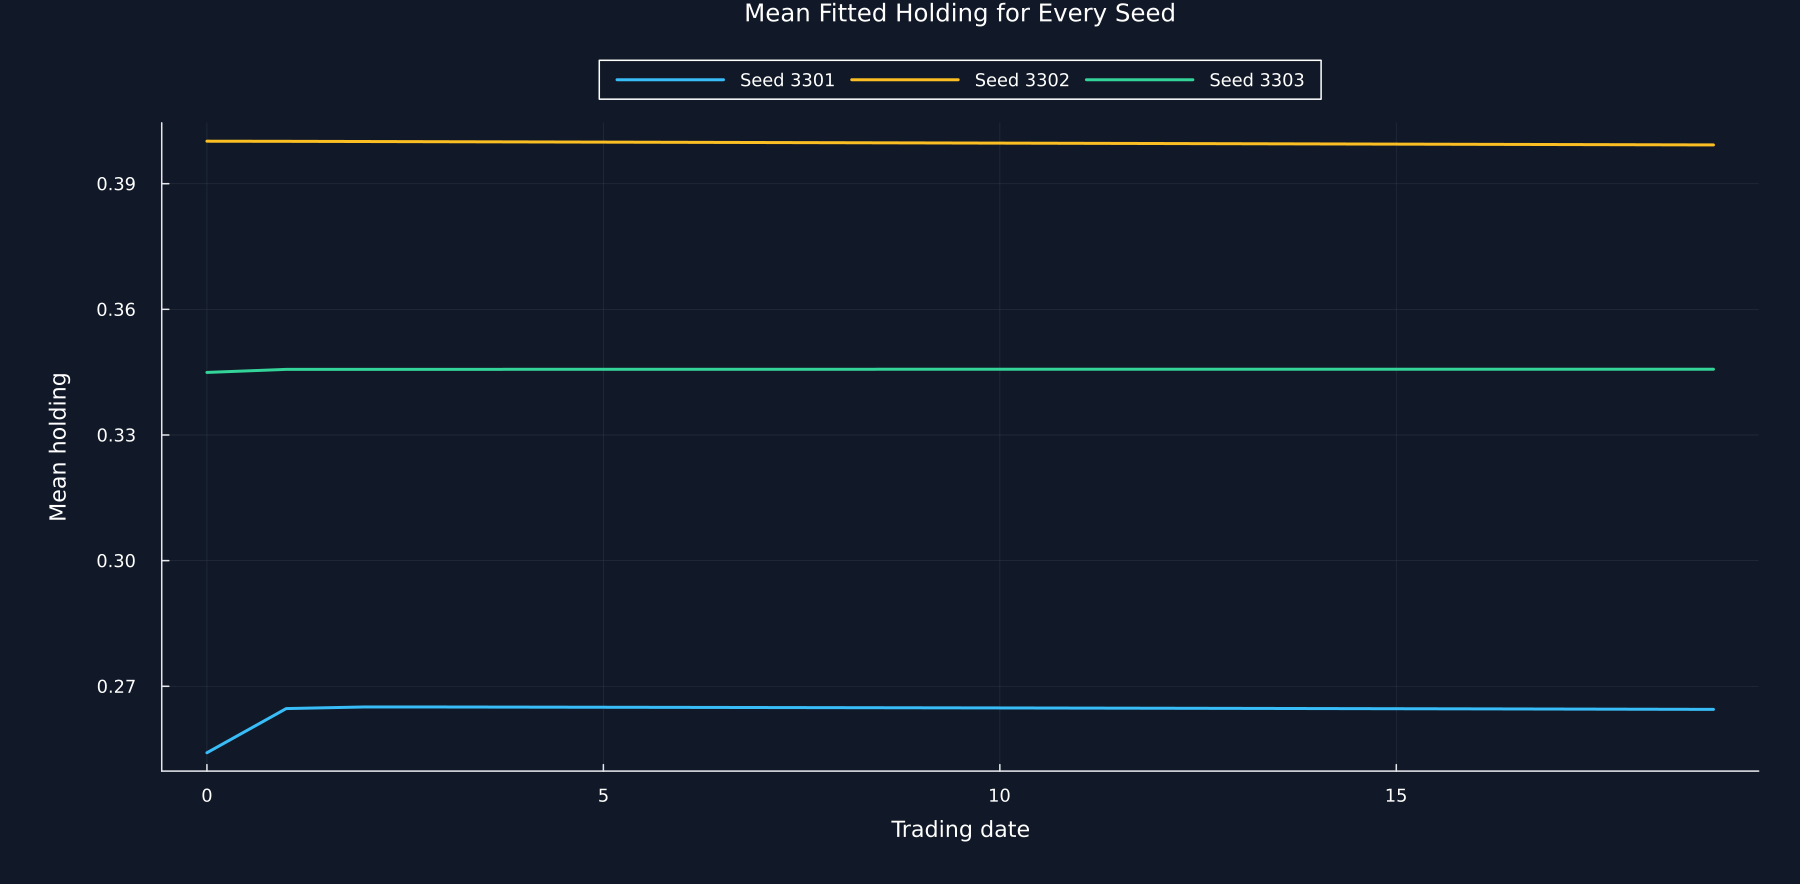

In [3]:
metric_rows = NamedTuple[]
pnl_frame = DataFrame()
holding_frame = DataFrame("Trading date"=>0:design.steps-1)
for seed in training_seeds
    seed_model = fitted_model(seed)
    seed_positions = seed_model(evaluation_prices;strike=design.strike,maturity=design.maturity)
    push!(metric_rows,metric_record("Learned seed $(seed)",evaluation_prices,seed_positions,design.strike,design.cost_rate,design.risk_aversion))
    pnl_frame[!,"Seed $(seed)"] = hedging_pnl(evaluation_prices,seed_positions;strike=design.strike,cost_rate=design.cost_rate)
    holding_frame[!,"Seed $(seed)"] = vec(mean(seed_positions;dims=1))
end
seed_metrics = rename!(DataFrame(metric_rows),METRIC_COLUMNS)
CSV.write(joinpath(artifacts,"primary_evaluation_metrics.csv"),seed_metrics)
table(seed_metrics,"deep_hedging_learned_seed_metrics","Independent outcomes for every declared learned policy.")
risks = seed_metrics[!,"Entropic risk"]
seed_summary = DataFrame("Quantity"=>["Smallest learned-policy risk","Largest learned-policy risk","Mean learned-policy risk","Risk range"],"Value"=>[minimum(risks),maximum(risks),mean(risks),maximum(risks)-minimum(risks)])
table(seed_summary,"deep_hedging_seed_outcome_summary","Range of retained learned-policy outcomes across the three seeds.")
save_data(pnl_frame,paths,"deep_hedging_learned_seed_cashflows")
figure = plot(;title="Independent Cash Flows for Every Learned Policy",xlabel="Terminal cash flow",ylabel="Density",legend=:outertop,legend_columns=3,size=(1200,590))
for (name,color) in zip(names(pnl_frame),[palette.cyan,palette.amber,palette.green])
    draw_histogram!(figure,pnl_frame[!,name],70;color,label=name,density=true,outline=true)
end
save_figure(figure,paths,"deep_hedging_learned_seed_cashflows")
save_data(holding_frame,paths,"deep_hedging_mean_holdings_by_seed")
figure = plot(;title="Mean Fitted Holding for Every Seed",xlabel="Trading date",ylabel="Mean holding",legend=:outertop,legend_columns=3,size=(1200,590))
for (name,color) in zip(names(holding_frame)[2:end],[palette.cyan,palette.amber,palette.green])
    plot!(figure,holding_frame[!,"Trading date"],holding_frame[!,name];color,label=name)
end
save_figure(figure,paths,"deep_hedging_mean_holdings_by_seed")
nothing
